# Butler–Volmer Kinetics, Nicholson $\Psi$, & Tafel Analysis

## 1. Goal

Explore the transition from reversible to quasi-reversible and irreversible CV as $k^0$ decreases, extract $k^0$ via Nicholson's method (`analyze_nicholson()`), and extract $\alpha$ and $k^0$ in the irreversible regime via `analyze_tafel()`.

## 2. Physical Setup

We vary $k^0 \in \{10^{-2}, 10^{-4}, 3 \times 10^{-5}, 10^{-6}\}\text{ m/s}$ at fixed $\alpha = 0.5$ and $v = 0.1\text{ V/s}$.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

from softpotato.geometry import PlanarGeometry
from softpotato.reactions import ButlerVolmer, Species
from softpotato.techniques import (
    CyclicVoltammetry,
    LinearSweepVoltammetry,
    analyze_nicholson,
    analyze_tafel,
    plot_tafel,
    simulate,
)

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
area = 7.07e-6
alpha = 0.5

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
geometry = PlanarGeometry(area)
cv = CyclicVoltammetry(E_start=0.5, E_vertex1=-0.5, E_vertex2=0.5, scan_rate=0.1, dE=0.002)

k0_values = [1.0e-2, 1.0e-4, 3.0e-5, 1.0e-6]

## 3. Simulation

We simulate CVs across the four $k^0$ values and an LSV at $k^0 = 10^{-6}\text{ m/s}$ for Tafel analysis.

In [2]:
cv_results = {
    k0: simulate(cv, [ox, red], geometry=geometry, kinetics=ButlerVolmer(k0=k0, alpha=alpha, E0=E0, n=1))
    for k0 in k0_values
}

lsv = LinearSweepVoltammetry(E_start=0.0, E_end=-0.4, scan_rate=0.05, dE=0.002)
lsv_irrev = simulate(
    lsv, [ox, red], geometry=geometry, kinetics=ButlerVolmer(k0=1.0e-7, alpha=alpha, E0=E0, n=1)
)

## 4. Diagnostics & Plots

We run `analyze_nicholson()` on the quasi-reversible CV ($k^0 = 3 \times 10^{-5}\text{ m/s}$) and `analyze_tafel()` on the irreversible LSV.

Nicholson (true k0 = 3.00e-5 m/s):
  delta_Ep = 136.8 mV, Psi = 0.256, k0 = 2.83e-05 m/s, regime = 'quasi-reversible'
Tafel (true alpha = 0.50, k0 = 1.00e-7 m/s):
  alpha = 0.461, k0 = 1.17e-07 m/s, slope = -128.3 mV/dec


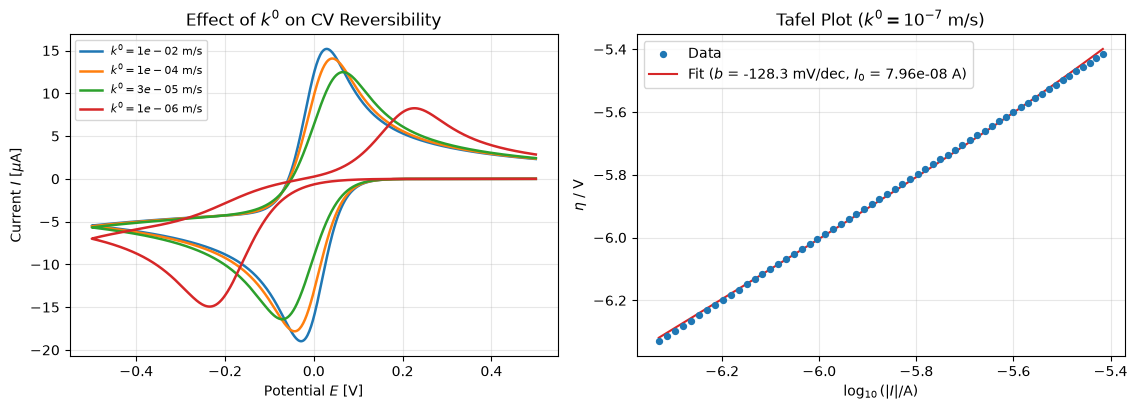

In [3]:
nich = analyze_nicholson(cv_results[3.0e-5], D=D, n=1)
print(f"Nicholson (true k0 = 3.00e-5 m/s):")
print(f"  delta_Ep = {nich.delta_Ep_mv:.1f} mV, Psi = {nich.psi:.3f}, k0 = {nich.k0:.2e} m/s, regime = {nich.regime!r}")

tafel_fit = analyze_tafel(
    lsv_irrev, E0=E0, overpotential_window=(-0.22, -0.10),
    n=1, area=area, c_bulk=c_bulk, branch="cathodic",
)
print(f"Tafel (true alpha = 0.50, k0 = 1.00e-7 m/s):")
print(f"  alpha = {tafel_fit.alpha:.3f}, k0 = {tafel_fit.k0:.2e} m/s, slope = {tafel_fit.slope_mv:.1f} mV/dec")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for k0, res in cv_results.items():
    axes[0].plot(res.potential, res.current * 1e6, lw=1.8, label=f"$k^0 = {k0:.0e}$ m/s")
axes[0].set_xlabel("Potential $E$ [V]")
axes[0].set_ylabel(r"Current $I$ [$\mu$A]")
axes[0].set_title("Effect of $k^0$ on CV Reversibility")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

plot_tafel(
    lsv_irrev, tafel_fit, E0=E0, overpotential_window=(-0.22, -0.10),
    branch="cathodic", ax=axes[1],
)
axes[1].set_title("Tafel Plot ($k^0 = 10^{-7}$ m/s)")

plt.tight_layout()
plt.show()

## 5. Key Takeaways

- High $k^0$ ($\Lambda \gg 10$) gives reversible Nernstian peaks ($\Delta E_p \approx 57\text{ mV}$).
- Intermediate $k^0$ widens $\Delta E_p$ and lowers peak height; `analyze_nicholson()` extracts $k^0$ from $\Delta E_p$.
- Low $k^0$ shifts the wave to large overpotentials where `analyze_tafel()` extracts $\alpha$ and $k^0$ from $\log_{10}|I|$ vs. $\eta$.
- **Next**: Read [Electrode Kinetics Concepts](../../concepts/electrochemistry/kinetics.md).